# Pruebas de disparidad en crédito justo: tasas de selección, regla de los cuatro quintos, paridad, probabilidades igualadas y calibración por grupo

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 05 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular la tasa de selección (aprobación) de cada grupo a partir de decisiones, y con ella la diferencia de paridad, la razón de impacto adverso y la marca de los cuatro quintos, sobre conteos exactos;
- probar una brecha de tasas con la prueba z de dos proporciones y la prueba exacta de Fisher, y decir por qué un valor p muy pequeño en una muestra muy grande no mide qué tan grande es la disparidad;
- enunciar el marco legal con honestidad: la regla de los cuatro quintos es un referente de empleo usado por analogía, la Regulación B enmendada en 2026 dice que la prueba de efectos no aplica bajo la ECOA, la Fair Housing Act es una ley aparte, y las disparidades brutas de tasas de HMDA son solo indicadores;
- calcular las métricas basadas en el resultado (igualdad de oportunidad, probabilidades igualadas, calibración y AUC por grupo) sobre datos plantados, y ver por qué no pueden correr sobre HMDA, que no tiene resultado;
- leer la comparación HMDA versionada de Delaware 2018 y 2019 (caso C21) y la batería de equidad de Taiwán versionada (caso C20), y reconstruir sus filas con el motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import inference, metrics, plants
from riskvalidation.fairness.metrics import SelectionRate
from riskvalidation.validation import fairness as vf

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

- **Los generadores de sesgo plantado del motor** (`riskvalidation.fairness.plants`): una cartera logística con un grupo protegido binario, una decisión y un resultado, y un sesgo plantado a la vez con la verdad conocida exacta. `ThresholdBiasPlant` aprueba al grupo protegido con un punto de corte menor en una `gap` en log-odds; `LabelNoiseBiasPlant` invierte una fracción de los resultados observados del grupo protegido aunque el modelo trata igual a ambos grupos. Sintéticos, desde una semilla, sin clase de licencia.
- **La comparación HMDA versionada de Delaware, 2018 a 2019** (`data/derived/C21/pair-2018-19.json`; propietario: este repositorio). HMDA son los datos de la Home Mortgage Disclosure Act publicados por el FFIEC y el CFPB (clase mirror-allowed; la frase de licencia de los datos está SIN VERIFICAR, y el documento lo dice). Contiene el número de solicitudes y aprobaciones por grupo de raza, etnia, sexo y edad (créditos originados o aprobados, acción tomada 1 y 2, contra negados, 3), las pruebas que corrió el pipeline y un bloque de declaraciones legales. **HMDA no tiene resultado** (ni incumplimiento ni pago) y retiene el puntaje de crédito, así que solo pueden correr las pruebas de tasas de selección.
- **La batería de equidad de Taiwán versionada del caso C20** (`data/derived/C20/perturbation-grid.json`; derivada de los datos de tarjetas de crédito de Taiwán de UCI, CC BY 4.0): doce filas del motor, cuatro pruebas por tres atributos (sexo, estado civil y tramo de edad) sobre la PD del modelo a un punto de corte fijo. La primera celda abre ambos documentos.

In [2]:
# Abrir ambos documentos versionados e imprimir el motor que horneó cada uno
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
taiwan = json.loads((ROOT / "data" / "derived" / "C20" / "perturbation-grid.json").read_text(encoding="utf-8"))
for label, doc in (("C21 pair-2018-19", hmda), ("C20 perturbation-grid", taiwan)):
    print(f'{label:22s} horneado con riskvalidation {doc["provenance"]["riskvalidation_version"]} | filas de prueba {len(doc["tests"])}')
print("filas de ajuste y de confirmación:", hmda["outputs"]["scope"]["rows_fit"], hmda["outputs"]["scope"]["rows_confirm"], "|", hmda["outputs"]["scope"]["state"])
print("etiqueta legal del documento:", hmda["outputs"]["legal"]["label"]["es"])

C21 pair-2018-19       horneado con riskvalidation 0.8.1 | filas de prueba 87
C20 perturbation-grid  horneado con riskvalidation 0.8.1 | filas de prueba 16
filas de ajuste y de confirmación: 36515 41834 | DE
etiqueta legal del documento: sin afirmación legal


## Método

### Paso 1: tasas de selección

Para una decisión favorable $d_i \in \{0, 1\}$ (aquí: aprobado) y una etiqueta de grupo $g_i$, la tasa de selección del grupo $g$ es $r_g = x_g / n_g$, con $x_g$ el conteo favorable y $n_g$ el tamaño. El motor trabaja sobre los **conteos**, con aritmética entera exacta, y redondea una sola vez cuando produce un flotante. El documento versionado guarda los conteos por grupo, así que la celda siguiente reconstruye un vector de decisiones y un vector de grupos con exactamente esos conteos (es el agregado, no las 31.000 solicitudes individuales) y llama a `group_selection_rates` del motor. Las tasas deben ser iguales a las versionadas.

In [3]:
# Reconstruir decisiones y grupos desde los conteos versionados del atributo raza y calcular las tasas de selección con el motor
def arrays_of(attribute):
    decision = np.concatenate([np.repeat([1, 0], [g["n_approved"], g["n_denied"]]) for g in attribute["groups"]])
    group = np.concatenate([np.repeat(g["group"], g["n"]) for g in attribute["groups"]])
    return decision, group


race = hmda["outputs"]["attributes"][0]
decision, group = arrays_of(race)
rates = metrics.group_selection_rates(decision, group)
print(race["field"], "| grupo de referencia:", race["reference_group"], "| filas:", len(decision))
for g in race["groups"]:
    r = rates[g["group"]]
    print(f'{g["group"]:44s} n {r.n:6d} aprobados {r.favourable:6d} tasa {r.rate:.4f} | igual a la versionada {"sí" if r.rate == g["selection_rate"] else "no"}')

derived_race | grupo de referencia: White | filas: 31342
American Indian or Alaska Native             n    139 aprobados     71 tasa 0.5108 | igual a la versionada sí
Asian                                        n   1359 aprobados   1037 tasa 0.7631 | igual a la versionada sí
Black or African American                    n   5370 aprobados   3315 tasa 0.6173 | igual a la versionada sí
Native Hawaiian or Other Pacific Islander    n     86 aprobados     50 tasa 0.5814 | igual a la versionada sí
White                                        n  24293 aprobados  18839 tasa 0.7755 | igual a la versionada sí
2 or more minority races                     n     95 aprobados     47 tasa 0.4947 | igual a la versionada sí


### Paso 2: paridad, razón de impacto adverso y regla de los cuatro quintos

Con un grupo de referencia $h$ (la elección del dossier para raza es el grupo mayor, White):

$$\text{diferencia de paridad: } r_g - r_h, \qquad \text{razón de impacto adverso: } \mathrm{AIR}_g = \frac{r_g}{r_h}.$$

La prueba de **paridad demográfica** informa la mayor diferencia absoluta contra la referencia y es verde hasta una tolerancia de 0,05 (una convención), ámbar sobre ella, nunca roja. La regla de los cuatro quintos de las pautas de empleo de EE. UU. (29 CFR 1607.4(D)) compara cada grupo con el grupo de **mayor tasa** $t$ (no necesariamente la referencia) y marca a un grupo cuya tasa es menor que cuatro quintos de ella:

$$\text{marca}_g \iff 5\,x_g\,n_t < 4\,x_t\,n_g .$$

Ambas reglas se deciden sobre los enteros, nunca sobre un flotante que podría fallar el límite por una unidad en el último lugar: 60 de 100 contra 75 de 100 tiene una razón en flotante de $0{,}7999999999999999$ y una razón exacta de $4/5$, que **no** se marca. **La regla de los cuatro quintos es un referente de empleo usado por analogía; no es un umbral de la ley de crédito**, y el resultado del motor lo dice en un campo propio. La celda siguiente muestra el límite y luego calcula las diferencias de paridad, las razones y las marcas de los grupos de raza.

In [4]:
# El caso límite 60/100 contra 75/100, luego diferencias de paridad, razones y marcas de cuatro quintos de los grupos de raza
edge = metrics.group_selection_rates(np.r_[np.ones(60), np.zeros(40), np.ones(75), np.zeros(25)].astype(int), np.r_[np.repeat("A", 100), np.repeat("B", 100)])
print("60/100 contra 75/100 | razón en flotante", (60 / 100) / (75 / 100), "| marcado por el motor", ("sí" if metrics.four_fifths_flag(edge).flag["A"] else "no"))
reference = race["reference_group"]
parity = metrics.demographic_parity_difference(rates, reference)
air = metrics.adverse_impact_ratio(rates, reference)
four_fifths = metrics.four_fifths_flag(rates)
print("grupo de mayor tasa:", four_fifths.highest_rate_group, "| etiqueta del referente:", four_fifths.label, "| es un umbral de la ley de crédito:", ("sí" if four_fifths.is_credit_law_threshold else "no"))
for g in race["groups"]:
    name = g["group"]
    print(f"{name:44s} diferencia {parity[name]:+.4f} | AIR {air[name]:.4f} | marca {'sí' if four_fifths.flag[name] else 'no'}")

60/100 contra 75/100 | razón en flotante 0.7999999999999999 | marcado por el motor no
grupo de mayor tasa: White | etiqueta del referente: employment benchmark | es un umbral de la ley de crédito: no
American Indian or Alaska Native             diferencia -0.2647 | AIR 0.6587 | marca sí
Asian                                        diferencia -0.0124 | AIR 0.9840 | marca no
Black or African American                    diferencia -0.1582 | AIR 0.7960 | marca sí
Native Hawaiian or Other Pacific Islander    diferencia -0.1941 | AIR 0.7497 | marca sí
White                                        diferencia +0.0000 | AIR 1.0000 | marca no
2 or more minority races                     diferencia -0.2808 | AIR 0.6380 | marca sí


Las pruebas del motor envuelven estas funciones en filas `TestResult` con una luz. La celda siguiente reconstruye las tasas de los cuatro atributos del documento (raza, etnia, sexo y edad), llama a las pruebas `demographic_parity` y `adverse_impact` del motor y compara la métrica y la luz con la fila versionada.

In [5]:
# Para cada atributo reconstruir las tasas desde los conteos versionados, llamar a las dos pruebas del motor y comparar con las filas versionadas
committed = {(t["test_id"], t["segment"]): t for t in hmda["tests"]}
print(f'{"atributo":20s} {"grupos":>7s} {"brecha":>11s} {"luz":>6s} {"AIR mín":>8s} {"luz":>6s} igual a la versionada')
for attribute in hmda["outputs"]["attributes"]:
    dec, grp = arrays_of(attribute)
    r = metrics.group_selection_rates(dec, grp)
    dp = vf.demographic_parity("hmda", r, attribute["reference_group"])
    ai = vf.adverse_impact("hmda", r, attribute["reference_group"])
    old_dp, old_ai = committed[("fair.demographic_parity", attribute["field"])], committed[("fair.adverse_impact", attribute["field"])]
    same = abs(dp.metric - old_dp["metric"]) < 1e-12 and dp.light.value == old_dp["light"] and abs(ai.metric - old_ai["metric"]) < 1e-12 and ai.light.value == old_ai["light"]
    print(f'{attribute["field"]:20s} {len(r):7d} {dp.metric:11.4f} {dp.light.value:>6s} {ai.metric:8.4f} {ai.light.value:>6s} {"sí" if same else "no"}')

atributo              grupos      brecha    luz  AIR mín    luz igual a la versionada
derived_race               6      0.2808  amber   0.6380  amber sí
derived_ethnicity          2      0.0881  amber   0.8829  green sí
derived_sex                2      0.0019  green   0.9974  green sí
applicant_age              7      0.0933  amber   0.8082  green sí


### Paso 3: ¿es una brecha más que el azar? La prueba z y la prueba exacta de Fisher

Una diferencia de tasas se puede probar. Para el grupo 1 con $x_1$ de $n_1$ y el grupo 2 con $x_2$ de $n_2$, el estadístico z de dos proporciones combinado y su valor p de dos colas son

$$z = \frac{x_1/n_1 - x_2/n_2}{\sqrt{\hat{p}(1-\hat{p})\,(1/n_1 + 1/n_2)}}, \quad \hat{p} = \frac{x_1 + x_2}{n_1 + n_2}, \qquad p = 2\bigl(1 - \Phi(|z|)\bigr),$$

y la prueba exacta de Fisher usa la ley hipergeométrica sobre la tabla de $2 \times 2$ (el motor informa la razón de momios muestral). La luz es roja bajo 0,01, ámbar bajo 0,05. Un valor p responde "¿es la brecha compatible con el azar?", **no** "¿es grande la brecha?": con 24.293 solicitudes en el grupo de referencia, una brecha de pocos puntos está lejos del azar. La celda siguiente prueba cada grupo contra la referencia, reconstruye las filas versionadas y compara.

In [6]:
# Probar cada grupo de raza contra la referencia con la prueba z y la de Fisher y comparar con las filas versionadas
ref = rates[reference]
print(f'{"grupo":44s} {"z":>8s} {"p z":>9s} {"p Fisher":>9s} {"razón de momios":>14s} luz igual')
for g in race["groups"]:
    if g["group"] == reference:
        continue
    s = rates[g["group"]]
    z = inference.two_proportion_z_test(s.favourable, s.n, ref.favourable, ref.n)
    f = inference.fisher_exact_test(s.favourable, s.n, ref.favourable, ref.n)
    row = vf.two_proportion_z("hmda", s.favourable, s.n, ref.favourable, ref.n)
    old = committed[("fair.two_proportion_z", f'derived_race|{g["group"]} vs {reference}')]
    print(f'{g["group"]:44s} {z.statistic:8.3f} {z.p_value:9.2e} {f.p_value:9.2e} {f.odds_ratio:14.4f} {row.light.value:5s} {"sí" if abs(row.statistic - old["statistic"]) < 1e-9 and row.light.value == old["light"] else "no"}')

grupo                                               z       p z  p Fisher razón de momios luz igual
American Indian or Alaska Native               -7.440  1.01e-13  1.21e-11         0.3023 red   sí
Asian                                          -1.068  2.86e-01  2.86e-01         0.9324 green sí
Black or African American                     -24.124 1.40e-128 3.00e-120         0.4670 red   sí
Native Hawaiian or Other Pacific Islander      -4.302  1.70e-05  7.36e-05         0.4021 red   sí
2 or more minority races                       -6.534  6.40e-11  3.03e-09         0.2835 red   sí


### Paso 4: el marco legal, como lo enuncia el documento versionado

El documento lleva las declaraciones legales que el pipeline leyó de fuentes primarias, de modo que ningún número en él se lea como más de lo que es. La celda siguiente las imprime: la etiqueta de todo el documento, la frase de la Regulación B enmendada el 2026-04-22 (12 CFR 1002.6(a), 91 FR 21668), la declaración de los Procedimientos Interagenciales sobre las disparidades brutas de HMDA, y las marcas que dicen que las tasas incondicionales son solo indicadores y la disparidad controlada una aproximación de evidencia comparativa. El cuaderno no las interpreta más allá de lo que dicen.

In [7]:
# Imprimir las declaraciones legales que lleva el documento, en el idioma de este cuaderno donde tiene dos
legal = hmda["outputs"]["legal"]
print("etiqueta:", legal["label"]["es"])
print("Regulación B:", legal["regulation_b"]["citation"])
print("  cita textual, en inglés:", legal["regulation_b"]["quote"])
print("Procedimientos interagenciales:", legal["procedures"]["citation"])
print("  cita textual, en inglés:", legal["procedures"]["quote"])
print("las tasas incondicionales son:", legal["unconditional_rates_are"], "| la disparidad controlada es:", legal["controlled_disparity_is"], "| un hallazgo de infracción:", ("sí" if legal["is_a_finding_of_violation"] else "no"))
print("licencia de los datos:", hmda["outputs"]["licence"]["status"])

etiqueta: sin afirmación legal
Regulación B: 12 CFR 1002.6(a), as amended at 91 FR 21668 (2026-04-22, effective 2026-07-21)
  cita textual, en inglés: The Act does not provide that the 'effects test' applies for determining whether there is discrimination in violation of the Act.
Procedimientos interagenciales: Interagency Fair Lending Examination Procedures, August 2009, appendix, printed page 26
  cita textual, en inglés: Gross HMDA denial or approval rate disparities are not appropriate for disproportionate adverse impact analysis because they typically cannot be attributed to a specific policy or criterion.
las tasas incondicionales son: indicators-only | la disparidad controlada es: approximation-of-comparative-evidence | un hallazgo de infracción: no
licencia de los datos: UNVERIFIED


### Paso 5: las métricas basadas en el resultado, sobre sesgo plantado

Con un resultado $y$ (aquí 1 = pagó), una decisión $d$ (1 = aprobado) y un grupo, las métricas de Hardt, Price y Srebro (2016) comparan tasas de error:

$$\mathrm{TPR}_g = P(d=1 \mid y=1, g), \qquad \mathrm{FPR}_g = P(d=1 \mid y=0, g),$$

$$\text{brecha de igualdad de oportunidad} = \max_g \mathrm{TPR}_g - \min_g \mathrm{TPR}_g, \qquad \text{brecha de probabilidades igualadas} = \max\bigl(\text{brecha de TPR},\; \text{brecha de FPR}\bigr).$$

La calibración por grupo es el error de calibración esperado de la PD dentro de cada grupo, y el AUC por grupo es el AUC del puntaje dentro de cada grupo. Las cuatro necesitan un resultado: sobre un conjunto que no declara ninguno, como HMDA, el motor se niega con un mensaje. La celda siguiente muestra la negativa sobre las decisiones de HMDA, y luego las métricas en tres plantas: sin sesgo, con sesgo de umbral (el grupo protegido se aprueba con un punto de corte menor en 0,8 en log-odds) y con sesgo de ruido de etiqueta (el modelo trata igual a los grupos pero el 20% de los resultados observados del grupo protegido está invertido).

In [8]:
# La negativa sobre HMDA, luego igualdad de oportunidad, probabilidades igualadas, calibración y AUC por grupo en tres conjuntos plantados
try:
    metrics.equalized_odds_difference(None, decision, group)
except ValueError as error:
    print("rechazado:", type(error).__name__, "| el motor nombra el resultado que falta:", ("sí" if "outcome: none" in str(error) else "no"))
draws = {}
specs = (("sin sesgo", plants.ThresholdBiasPlant(n=20000, gap=0.0, seed=1)),
         ("sesgo de umbral", plants.ThresholdBiasPlant(n=20000, gap=0.8, seed=1)),
         ("sesgo de ruido de etiqueta", plants.LabelNoiseBiasPlant(n=20000, noise=0.2, seed=1)))
for label, plant in specs:
    d = plant.draw_default()
    draws[label] = d
    pd_model = np.clip(d["pd"], 1e-6, 1 - 1e-6)
    eo = metrics.equal_opportunity_difference(d["y"], d["decision"], d["group"])
    eq = metrics.equalized_odds_difference(d["y"], d["decision"], d["group"])
    cal = metrics.calibration_within_groups(pd_model, d["defaults"], d["group"])
    auc = metrics.auc_by_group(pd_model, d["defaults"], d["group"])
    rate = metrics.group_selection_rates(d["decision"], d["group"])
    print(f'{label:26s} tasas de selección {rate["0"].rate:.3f} / {rate["1"].rate:.3f} | igualdad de oportunidad {eo:.4f} | prob. igualadas {eq:.4f}')
    print(f'{"":26s} ECE por grupo {cal["0"]:.4f} / {cal["1"]:.4f} | AUC por grupo {auc["0"]:.4f} / {auc["1"]:.4f}')

rechazado: ValueError | el motor nombra el resultado que falta: sí
sin sesgo                  tasas de selección 0.704 / 0.702 | igualdad de oportunidad 0.0019 | prob. igualadas 0.0157
                           ECE por grupo 0.0093 / 0.0132 | AUC por grupo 0.7671 / 0.7740
sesgo de umbral            tasas de selección 0.704 / 0.446 | igualdad de oportunidad 0.2518 | prob. igualadas 0.2775
                           ECE por grupo 0.0093 / 0.0132 | AUC por grupo 0.7671 / 0.7740
sesgo de ruido de etiqueta tasas de selección 0.704 / 0.702 | igualdad de oportunidad 0.0389 | prob. igualadas 0.1229
                           ECE por grupo 0.0093 / 0.0977 | AUC por grupo 0.7671 / 0.6458


### Paso 6: la batería de Taiwán versionada

El modelo de Taiwán del caso C20 se revisó con las mismas cuatro métricas basadas en el resultado por sexo, estado civil y tramo de edad. Las doce filas están rotuladas en el documento como "evidencia de equidad rotulada", sin marca de cuatro quintos y sin prueba de tasas por grupo. La celda siguiente las imprime con la luz que recibe cada una de los puntos de corte del motor (0,05 ámbar, 0,10 rojo, convenciones), y reconstruye una de ellas desde las tasas por grupo versionadas.

In [9]:
# Imprimir las doce filas versionadas de la batería de Taiwán y reconstruir un valor de probabilidades igualadas desde las tasas por grupo
battery = taiwan["outputs"]["fairness_battery"]
print("etiqueta:", battery["label"], "| modelo:", battery["model"], "| filas:", len(battery["rows"]))
for r in battery["rows"]:
    print(f'{r["test_id"]:32s} {r["attribute"]:10s} valor {r["value"]:.4f} grupos {len(r["groups"])} luz {r["light"]}')
row = next(t for t in taiwan["tests"] if t["test_id"] == "fair.equalized_odds" and t["segment"] == "sex")
rates_by_group = row["extras"]["rates_by_group"]
tpr_gap = max(g["tpr"] for g in rates_by_group.values()) - min(g["tpr"] for g in rates_by_group.values())
fpr_gap = max(g["fpr"] for g in rates_by_group.values()) - min(g["fpr"] for g in rates_by_group.values())
print("fair.equalized_odds / sex | versionado", round(row["metric"], 6), "| max(TPR, FPR) brechas desde las tasas por grupo", round(max(tpr_gap, fpr_gap), 6))

etiqueta: labelled-fairness-battery | modelo: uci-taiwan | filas: 12
fair.equalized_odds              sex        valor 0.0431 grupos 2 luz green
fair.equalized_odds              age        valor 0.1083 grupos 4 luz red
fair.equalized_odds              marital_status valor 0.1127 grupos 3 luz red
fair.equal_opportunity           sex        valor 0.0149 grupos 2 luz green
fair.equal_opportunity           age        valor 0.1003 grupos 4 luz red
fair.equal_opportunity           marital_status valor 0.0325 grupos 3 luz green
fair.calibration_within_groups   sex        valor 0.0877 grupos 2 luz amber
fair.calibration_within_groups   age        valor 0.1047 grupos 4 luz red
fair.calibration_within_groups   marital_status valor 0.1565 grupos 3 luz red
fair.auc_by_group                sex        valor 0.0120 grupos 2 luz green
fair.auc_by_group                age        valor 0.0211 grupos 4 luz green
fair.auc_by_group                marital_status valor 0.0568 grupos 3 luz amber
fair.equalize

### Paso 7: la evidencia, dibujada

Izquierda: la tasa de selección de cada grupo de raza de Delaware 2018 contra la tasa de referencia, con la línea de los cuatro quintos (80% de la mayor tasa). Derecha: la brecha de probabilidades igualadas de las tres plantas.

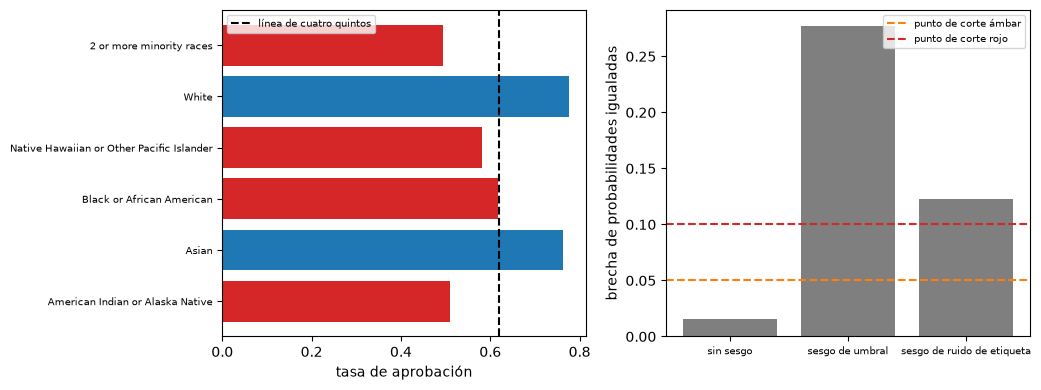

In [10]:
# Izquierda: tasas de selección por grupo de raza con la línea de cuatro quintos; derecha: brecha de probabilidades igualadas de las tres plantas
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
names = [g["group"] for g in race["groups"]]
left.barh(names, [rates[n].rate for n in names], color=["tab:red" if four_fifths.flag[n] else "tab:blue" for n in names])
left.axvline(0.8 * rates[four_fifths.highest_rate_group].rate, color="black", linestyle="--", label="línea de cuatro quintos")
left.set_xlabel("tasa de aprobación")
left.tick_params(axis="y", labelsize=7)
left.legend(fontsize=7)
gaps = [metrics.equalized_odds_difference(d["y"], d["decision"], d["group"]) for d in draws.values()]
right.bar(range(3), gaps, color="tab:gray")
right.set_xticks(range(3))
right.set_xticklabels(list(draws), fontsize=7)
right.axhline(0.05, color="tab:orange", linestyle="--", label="punto de corte ámbar")
right.axhline(0.10, color="tab:red", linestyle="--", label="punto de corte rojo")
right.set_ylabel("brecha de probabilidades igualadas")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **Los conteos reproducen exactamente las tasas versionadas.** Los grupos de raza de Delaware 2018 tienen tasas de aprobación desde 0,5108 (indígena americano o nativo de Alaska, 139 solicitudes) hasta 0,7755 (White, 24.293 solicitudes), y cada tasa reconstruida por el motor es igual a la versionada. Los cuatro atributos (raza, etnia, sexo y edad) dan la misma métrica y la misma luz que las filas versionadas.
- **La brecha de paridad y la marca de cuatro quintos responden preguntas distintas.** Para raza la mayor brecha contra el grupo White es 0,2808 (ámbar, una convención de 0,05) y cuatro de los otros cinco grupos quedan marcados contra el grupo de mayor tasa: el grupo Black tiene una razón de 0,7960, bajo 0,8 por poco, el grupo indígena americano 0,6587. El grupo asiático (0,9840) no se marca y su prueba z es compatible con el azar (z = -1,068, p = 0,286). Para etnia la brecha es 0,0881 (ámbar) con una razón de 0,8829 (verde); para edad la brecha es 0,0933 (ámbar) y la menor razón 0,8082 (verde); para sexo la brecha es 0,0019 (verde).
- **Un valor p no es un tamaño.** La prueba z del grupo Black contra el grupo White da z = -24,124 y p = 1,40e-128, y el grupo indígena americano z = -7,440 con p = 1,01e-13, desde 139 solicitudes. Ambos son rojos. Las razones de momios (0,4670 y 0,3023) dicen qué tan grande, lo que el valor p no dice. Los valores p exactos de Fisher concuerdan en signo y orden de magnitud. El motor reproduce las luces de todas las filas versionadas.
- **El marco legal acota lo que significan las tasas.** El documento está rotulado "sin afirmación legal". Lleva la frase de la Regulación B enmendada (12 CFR 1002.6(a)) según la cual la ley no dispone que se aplique la prueba de efectos, la frase de los Procedimientos Interagenciales según la cual las disparidades brutas de tasas de HMDA no son apropiadas para un análisis de impacto adverso desproporcionado, y las marcas de que las tasas incondicionales son solo indicadores y de que un hallazgo de infracción es falso. El resultado de cuatro quintos lleva `is_credit_law_threshold = False`, y la licencia de los datos de HMDA está SIN VERIFICAR. Ninguna de las pruebas de este cuaderno decide discriminación.
- **Las métricas basadas en el resultado necesitan un resultado y encuentran lo plantado.** El motor se niega a calcularlas sobre HMDA. En las plantas: sin sesgo la brecha de igualdad de oportunidad es 0,0019 y la de probabilidades igualadas 0,0157; con el sesgo de umbral las tasas de selección son 0,704 y 0,446 y las brechas 0,2518 y 0,2775. Con ruido de etiqueta las tasas de selección son las mismas (0,704 y 0,702) porque el modelo trata igual a ambos grupos, y sin embargo la brecha de probabilidades igualadas es 0,1229, el error de calibración del grupo protegido es 0,0977 contra 0,0093 y su AUC 0,6458 contra 0,7671: lo que está mal es el resultado observado, no el modelo. Un validador que encuentra esas brechas debe preguntar primero si el resultado se mide igual en ambos grupos.
- **La batería de Taiwán versionada da un cuadro mixto.** De las doce filas, las brechas de probabilidades igualadas e igualdad de oportunidad por edad (0,1083 y 0,1003) y la de probabilidades igualadas por estado civil (0,1127) son rojas, la calibración por grupo es roja por edad (0,1047) y estado civil (0,1565) y ámbar por sexo (0,0877), y el AUC por grupo es verde para sexo y edad y ámbar para estado civil (0,0568). Las filas son evidencia rotulada sin marca de cuatro quintos; el valor de probabilidades igualadas por sexo se reconstruye desde las tasas por grupo (0,043078) y es igual al versionado. Todas las filas se hornearon con riskvalidation 0.8.1.

Lo que los resultados no muestran: ninguna prueba aquí establece una causa, y las tasas brutas de aprobación mezclan toda diferencia entre las solicitudes de los grupos; las luces del motor son convenciones (0,05 y 0,10, 5% y 1%) y la regla de los cuatro quintos no es un umbral de la ley de crédito; las plantas son sintéticas; y el modelo de Taiwán es un modelo de investigación, no el de un prestamista.

## Resumen

- Las tasas de selección se calculan sobre conteos exactos; la paridad, la razón de impacto adverso y la marca de cuatro quintos se deciden sobre los enteros, y la regla de los cuatro quintos es un referente de empleo usado por analogía, nunca un umbral de la ley de crédito.
- Una prueba z de dos proporciones y la prueba exacta de Fisher dicen si una brecha es compatible con el azar; con miles de solicitudes rechazan para brechas pequeñas, así que el tamaño de la brecha y la razón de momios se leen a su lado.
- La comparación HMDA versionada de Delaware 2018 la reproduce el motor desde sus conteos para raza, etnia, sexo y edad; está rotulada "sin afirmación legal", sus tasas son solo indicadores y la licencia de los datos está SIN VERIFICAR.
- Las métricas basadas en el resultado (igualdad de oportunidad, probabilidades igualadas, calibración y AUC por grupo) necesitan un resultado y se niegan a correr sin uno; un sesgo de ruido de etiqueta muestra que una brecha en ellas puede venir del resultado y no del modelo.
- La batería de Taiwán versionada tiene filas rojas por edad y estado civil, y cada fila es evidencia rotulada, no un hallazgo de infracción.

**Qué probar después.** El cuaderno 07 pregunta qué queda de una disparidad tras los controles permitidos, si se repite el año siguiente y qué encuentra una prueba de situación.

## Referencias

- Hardt, M., Price, E. y Srebro, N. (2016), Equality of opportunity in supervised learning, arXiv 1610.02413. https://arxiv.org/abs/1610.02413
- 29 CFR 1607.4(D), Uniform Guidelines on Employee Selection Procedures: la regla de los cuatro quintos, un referente de empleo. https://www.law.cornell.edu/cfr/text/29/1607.4
- CFPB (2026), Equal Credit Opportunity Act (Regulation B), regla final, 91 FR 21620, vigente desde 2026-07-21. https://www.govinfo.gov/content/pkg/FR-2026-04-22/pdf/2026-07804.pdf
- OCC, FDIC, Federal Reserve Board, OTS y NCUA (2009), Interagency Fair Lending Examination Procedures. https://www.federalreserve.gov/boarddocs/caletters/2009/0906/09-06_attachment.pdf
- Kozodoi, N., Jacob, J. y Lessmann, S. (2022), Fairness in credit scoring: assessment, implementation and profit implications, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.023
- FFIEC y CFPB, publicación de datos de la Home Mortgage Disclosure Act (la frase de licencia de los datos está SIN VERIFICAR). https://ffiec.cfpb.gov/data-publication/
- Yeh, I-C. y Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), las tarjetas de Taiwán de las variantes de C20. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients